# Nước Dã Viên tăng mạnh khi hai trạm mưa Model B ít mưa

Tìm và mô tả những mốc/đợt **nước đã tăng**, hai trạm phía Tây `750062` (Hồng Thái) và `750007` (Nhâm) có tổng số đo mưa 24 giờ thấp, trong khi trạm khác mưa cao. Phân tích **toàn snapshot** và **chỉ train** độc lập. Không train model, không thay Model B, không ghi báo cáo/file phụ.

**Định nghĩa tại mốc t:** `rise12 = H(t) − H(t−12h)`, `rise24 = H(t) − H(t−24h)`; `R24(t)` là tổng số đo trong `(t−24h, t]`. Mặc định: ít nhất một mức tăng ≥200 mm, **cả hai** trạm B có R24 ≤20, và **ít nhất một trạm khác** có R24 ≥50. “Nước tăng cao” ở đây là **mức tăng**, không phải vượt báo động hoặc mực nước tuyệt đối cao; bảng vẫn ghi H(t).

**Đây là phân tích hồi cứu.** Mưa tới t không phải mưa có sẵn tại t−12/t−24. Không suy ra khả năng dự báo sớm, lỗi của Model B, quan hệ nhân quả hay nước ở trạm khác chắc chắn chảy về Dã Viên. Đơn vị tổng số đo giữ quy ước pipeline; khoảng tích lũy vật lý của bản ghi mưa nguồn chưa được xác minh.


In [1]:
from pathlib import Path
from io import BytesIO
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/ai").is_dir())
SNAPSHOT = ROOT / "reports/rain_regions_h12_h24_20261019"
DATASET = ROOT / "train_data/da_vien_1h_2026-10-15"
WEST = ["750062", "750007"]
RISE_MIN_MM = 200.0
WEST_MAX_24H = 20.0
OTHER_MIN_24H = 50.0
MIN_VALID_READINGS_PER_HOUR = 6
EVENT_GAP_HOURS = 6
TZ = "Asia/Ho_Chi_Minh"
DIRECTIONS = ["Bắc", "Đông", "Nam", "Tây"]
COLORS = dict(zip(DIRECTIONS, ["#2878b5", "#e58c27", "#39956a", "#9564a8"]))
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

def show():
    buffer = BytesIO()
    plt.gcf().savefig(buffer, format="png", bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close()

def local(timestamp):
    return pd.Timestamp(timestamp).tz_convert(TZ).strftime("%Y-%m-%d %H:%M")

def normalize_id(values):
    return values.astype(str).str.lstrip("0")

print({"rise_mm": RISE_MIN_MM, "west_max_24h": WEST_MAX_24H,
       "other_min_24h": OTHER_MIN_24H, "merge_gap_hours": EVENT_GAP_HOURS})

{'rise_mm': 200.0, 'west_max_24h': 20.0, 'other_min_24h': 50.0, 'merge_gap_hours': 6}


## 1. Nạp nguồn, metadata và kiểm tra tính đầy đủ
Dùng snapshot 55 trạm xuất từ PostgreSQL (19/10), khoảng quan trắc tới 15/10, đồng bộ với `hourly.csv` của Model B. Cần giữ các nguồn local này để chạy lại. Notebook dừng rõ ràng nếu nguồn không tồn tại, không tự chuyển sang giai đoạn khác.

Mỗi giờ mưa chỉ hợp lệ khi có ≥6 số đo hợp lệ, không có số đo invalid, tổng không âm; mọi giờ trong cửa sổ 24 giờ phải hợp lệ. Snapshot có median/max 6 số đo/giờ ở các trạm; quy tắc này kiểm tra độ đầy đủ, không khẳng định ý nghĩa tích lũy của số đo. Không nội suy hoặc điền 0. Mức tăng nước yêu cầu đủ mọi mốc nước trong cửa sổ 12/24 giờ.


In [2]:
paths = [SNAPSHOT / name for name in ["hourly_rain.csv.gz", "station_catalog.csv", "export.json"]]
paths += [DATASET / "hourly.csv", DATASET / "manifest.json", ROOT / "data/water_level_stations.csv.gz"]
for path in paths:
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu nguồn local cần thiết: {path}")

raw = pd.read_csv(paths[0], dtype={"station_id": str})
raw["station_id"] = normalize_id(raw.station_id)
raw["timestamp_utc"] = pd.to_datetime(raw.timestamp_utc, utc=True)
assert not raw.duplicated(["timestamp_utc", "station_id"]).any()
raw["rain_mm"] = pd.to_numeric(raw.rain_mm, errors="coerce")
raw["valid_hour"] = (raw.n_valid.ge(MIN_VALID_READINGS_PER_HOUR) & raw.n_invalid.eq(0)
                     & raw.rain_mm.ge(0) & np.isfinite(raw.rain_mm))
print("Quan trắc/giờ theo nguồn:")
display(raw.groupby("station_id").agg(hours=("n_valid", "size"),
    median_readings=("n_valid", "median"), max_readings=("n_valid", "max"),
    rejected_hours=("valid_hour", lambda x: int((~x).sum()))))
raw.loc[~raw.valid_hour, "rain_mm"] = np.nan

hourly = pd.read_csv(paths[3], usecols=["timestamp_utc", "water_level_depth"])
hourly["timestamp_utc"] = pd.to_datetime(hourly.timestamp_utc, utc=True)
assert not hourly.timestamp_utc.duplicated().any()
hourly = hourly.set_index("timestamp_utc").sort_index()
index = pd.date_range(hourly.index.min(), hourly.index.max(), freq="1h")
water = hourly.water_level_depth.reindex(index).replace([np.inf, -np.inf], np.nan)
rain = raw.pivot(index="timestamp_utc", columns="station_id", values="rain_mm").reindex(index)
assert set(WEST).issubset(rain.columns)
rain24 = rain.rolling(24, min_periods=24).sum()
rises = pd.DataFrame(index=index)
for h in [12, 24]:
    complete = water.rolling(h + 1, min_periods=h + 1).count().eq(h + 1)
    rises[f"rise_{h}h"] = (water - water.shift(h)).where(complete)
manifest = json.loads(paths[4].read_text())
train_spec = manifest["splits"]["train"]
train_start, train_end = pd.Timestamp(train_spec["start_utc"]), pd.Timestamp(train_spec["end_utc"])
train = pd.Series((index >= train_start) & (index <= train_end), index=index)
# Mọi dữ liệu trong lịch sử 24h (bao gồm H(t−24h)) phải thuộc train.
train_context = train.rolling(25, min_periods=25).sum().eq(25)
scopes = {"all": pd.Series(True, index=index), "train": train_context}
print("Toàn snapshot, UTC+7:", local(index.min()), "→", local(index.max()))
print("Train theo manifest, UTC+7:", local(train_start), "→", local(train_end))
print("All chứa cả các giờ purge giữa split; train chỉ dùng bên trong ranh train.")
display(json.loads(paths[2].read_text()))
quality = pd.DataFrame({"hour_coverage": rain.notna().mean(), "complete_24h_coverage": rain24.notna().mean()})
display(quality.loc[WEST].round(3))

Quan trắc/giờ theo nguồn:
Toàn snapshot, UTC+7: 2025-11-15 02:00 → 2026-10-15 14:00
Train theo manifest, UTC+7: 2025-11-15 02:00 → 2026-07-30 23:00
All chứa cả các giờ purge giữa split; train chỉ dùng bên trong ranh train.


,hours,median_readings,max_readings,rejected_hours
station_id,,,,
14690,8013,6.0,6,22
14696,8029,6.0,6,2
14699,8002,6.0,6,26
228005,4927,6.0,6,2
228006,6372,6.0,6,2
567011,8015,6.0,6,7
677493,8029,6.0,6,2
677851,8029,6.0,6,28
678628,8029,6.0,6,2


{'n_stations': 55,
 'station_hours': 431690,
 'start_utc': '2025-11-14 19:00:00+00:00',
 'end_utc': '2026-10-15 07:00:00+00:00',
 'aggregation': 'source sums in (t-1h,t]; missing not zero',
 'caution': 'Same source-sum convention as B; physical raw accumulation intervals not independently reverified',
 'database_read_only': True}

,hour_coverage,complete_24h_coverage
station_id,,
750062,0.998,0.963
750007,1.000,0.994


In [3]:
catalog = pd.read_csv(paths[1], dtype={"id": str}).rename(columns={"id": "station_id"})
catalog["station_id"] = normalize_id(catalog.station_id)
assert catalog.station_id.is_unique
water_meta = pd.read_csv(paths[5], dtype={"code": str})
da_vien = water_meta.loc[normalize_id(water_meta.code).eq("74647403")].iloc[0]
LON0, LAT0 = json.loads(da_vien.geom)["coordinates"][:2]
lat0 = np.radians(LAT0)
lat = np.radians(catalog.latitude.to_numpy(float))
dlon = np.radians(catalog.longitude.to_numpy(float) - LON0)
y = np.sin(dlon) * np.cos(lat)
x = np.cos(lat0) * np.sin(lat) - np.sin(lat0) * np.cos(lat) * np.cos(dlon)
catalog["bearing_deg"] = (np.degrees(np.arctan2(y, x)) + 360) % 360
angle = np.sin((lat - lat0) / 2)**2 + np.cos(lat0) * np.cos(lat) * np.sin(dlon / 2)**2
catalog["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(np.clip(angle, 0, 1)))
catalog["direction"] = catalog.bearing_deg.map(lambda b: DIRECTIONS[int((b + 45) // 90) % 4] if np.isfinite(b) else None)
catalog.loc[catalog.distance_km.lt(.001), "direction"] = None
catalog = catalog.set_index("station_id", drop=False)
other_ids = sorted(set(rain.columns) - set(WEST))
print("Mã không có metadata:", sorted(set(rain.columns) - set(catalog.index)))
print("Hướng là cung 90° so với Dã Viên: Bắc ±45°, Đông 45–135°, Nam 135–225°, Tây 225–315°.")
print("Không gán lưu vực hoặc đường nước từ hướng; giữ cả ứng viên khác cũng ở phía Tây.")
display(catalog.loc[WEST, ["name", "address", "latitude", "longitude", "direction", "bearing_deg", "distance_km"]].round(3))

Mã không có metadata: []
Hướng là cung 90° so với Dã Viên: Bắc ±45°, Đông 45–135°, Nam 135–225°, Tây 225–315°.
Không gán lưu vực hoặc đường nước từ hướng; giữ cả ứng viên khác cũng ở phía Tây.


,name,address,latitude,longitude,direction,bearing_deg,distance_km
station_id,,,,,,,
750062,Hồng Thái (A Lưới),UBND xã Hồng Thái,16.240,107.242,Tây,235.342,42.798
750007,Nhâm (A Lưới),Đồn biên phòng Nhâm,16.221,107.179,Tây,237.746,49.479


## 2. Nhận diện mốc và gộp thành đợt
Chỉ các giờ thỏa **đồng thời** tăng nước, hai trạm B ít mưa và trạm khác mưa cao mới được gắn cờ. Gộp mốc gắn cờ cách nhau ≤6 giờ thành một đợt, độc lập trong từng scope. Đây là “đợt thỏa điều kiện”, không mặc định là toàn bộ một trận lũ; các khoảng xen giữa không nhất thiết thỏa điều kiện.

Trạm nổi bật được chọn theo R24 cao nhất **tại một mốc thực sự thỏa cả ba điều kiện**. Bảng ghi mưa hai trạm B và mức tăng nước tại chính mốc đó. Đỉnh nước trong khoảng mốc gắn cờ được ghi riêng để tránh ghép cực đại ở những giờ khác nhau thành một bằng chứng giả.


In [4]:
def condition_masks(scope, rise_min=RISE_MIN_MM, west_max=WEST_MAX_24H, other_min=OTHER_MIN_24H):
    rising = rises.ge(rise_min).any(axis=1)
    west_known = rain24[WEST].notna().all(axis=1)
    west_low = west_known & rain24[WEST].le(west_max).all(axis=1)
    other_known = rain24[other_ids].notna().any(axis=1)
    other_high = rain24[other_ids].ge(other_min).any(axis=1)
    base = scope & rising & west_low
    return base, base & other_high, west_known, other_known

def event_groups(times, gap_hours=EVENT_GAP_HOURS):
    times = pd.DatetimeIndex(times).sort_values()
    if not len(times):
        return []
    groups = times.to_series().diff().gt(pd.Timedelta(hours=gap_hours)).cumsum()
    return [pd.DatetimeIndex(group.index) for _, group in times.to_series().groupby(groups)]

event_columns = ["scope", "event_id", "start_local", "end_local", "flagged_hours", "span_hours",
    "peak_level_in_span_mm", "evidence_time_local", "rise12_mm", "rise24_mm", "level_mm",
    "west_750062_24h", "west_750007_24h", "top_station", "top_name", "direction", "other_24h", "n_stations_high"]
evidence_columns = ["scope", "event_id", "station_id", "name", "address", "direction", "latitude", "longitude", "distance_km",
    "time_local", "rain24", "west_750062_24h", "west_750007_24h", "rise12_mm", "rise24_mm", "level_mm", "matched_hours"]
event_rows, evidence_rows, audit_rows = [], [], []
event_times, qualified_masks, base_masks = {}, {}, {}
for scope_name, scope in scopes.items():
    base, matched, west_known, other_known = condition_masks(scope)
    base_masks[scope_name], qualified_masks[scope_name] = base, matched
    groups = event_groups(index[matched])
    audit_rows.append(dict(scope=scope_name, scoped_hours=int(scope.sum()),
        rising_hours=int((scope & rises.ge(RISE_MIN_MM).any(axis=1)).sum()),
        rising_west_unknown=int((scope & rises.ge(RISE_MIN_MM).any(axis=1) & ~west_known).sum()),
        rising_west_low=int(base.sum()), no_other_data=int((base & ~other_known).sum()),
        matching_hours=int(matched.sum()), events=len(groups)))
    for number, times in enumerate(groups, 1):
        event_id = f"{scope_name}-{number:02d}"
        event_times[(scope_name, event_id)] = times
        candidates = rain24.loc[times, other_ids].where(lambda frame: frame.ge(OTHER_MIN_24H))
        top_sid = candidates.max().idxmax()
        t = candidates[top_sid].idxmax()
        meta = catalog.loc[top_sid]
        event_rows.append(dict(scope=scope_name, event_id=event_id,
            start_local=local(times.min()), end_local=local(times.max()), flagged_hours=len(times),
            span_hours=(times.max() - times.min()).total_seconds() / 3600 + 1,
            peak_level_in_span_mm=water.loc[times.min():times.max()].max(),
            evidence_time_local=local(t), rise12_mm=rises.loc[t, "rise_12h"], rise24_mm=rises.loc[t, "rise_24h"],
            level_mm=water.loc[t], west_750062_24h=rain24.loc[t, WEST[0]], west_750007_24h=rain24.loc[t, WEST[1]],
            top_station=top_sid, top_name=meta['name'], direction=meta.direction,
            other_24h=rain24.loc[t, top_sid], n_stations_high=int(candidates.notna().any().sum())))
        for sid in candidates.columns[candidates.notna().any()]:
            t_sid = candidates[sid].idxmax()
            m = catalog.loc[sid]
            evidence_rows.append(dict(scope=scope_name, event_id=event_id, station_id=sid, name=m['name'], address=m.address,
                direction=m.direction, latitude=m.latitude, longitude=m.longitude, distance_km=m.distance_km,
                time_local=local(t_sid), rain24=rain24.loc[t_sid, sid],
                west_750062_24h=rain24.loc[t_sid, WEST[0]], west_750007_24h=rain24.loc[t_sid, WEST[1]],
                rise12_mm=rises.loc[t_sid, "rise_12h"], rise24_mm=rises.loc[t_sid, "rise_24h"], level_mm=water.loc[t_sid],
                matched_hours=int(candidates[sid].notna().sum())))
events = pd.DataFrame(event_rows, columns=event_columns)
evidence = pd.DataFrame(evidence_rows, columns=evidence_columns)
display(pd.DataFrame(audit_rows))
for scope_name in scopes:
    display(Markdown(f"### Các đợt: {scope_name}"))
    group = events.loc[events.scope.eq(scope_name)]
    if group.empty:
        print("Không có đợt thỏa các ngưỡng hiện tại.")
    else:
        display(group.round(2))

,scope,scoped_hours,rising_hours,rising_west_unknown,rising_west_low,no_other_data,matching_hours,events
0,all,8029,260,1,125,0,26,7
1,train,6166,187,1,112,0,16,4


### Các đợt: all

,scope,event_id,start_local,end_local,flagged_hours,span_hours,peak_level_in_span_mm,evidence_time_local,rise12_mm,rise24_mm,level_mm,west_750062_24h,west_750007_24h,top_station,top_name,direction,other_24h,n_stations_high
0,all,all-01,2025-12-03 18:00,2025-12-03 23:00,6,6.0,869.27,2025-12-03 23:00,383.00,236.95,869.27,19.4,12.6,750066,Đỉnh Bạch Mã (Phú Lộc),Đông,377.0,36
1,all,all-02,2026-01-07 07:00,2026-01-07 07:00,1,1.0,466.00,2026-01-07 07:00,41.38,200.32,466.00,11.6,5.2,750066,Đỉnh Bạch Mã (Phú Lộc),Đông,193.8,12
2,all,all-03,2026-03-13 01:00,2026-03-13 02:00,2,2.0,515.68,2026-03-13 02:00,207.17,85.28,503.72,5.8,8.2,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,79.6,11
3,all,all-04,2026-04-26 01:00,2026-04-26 07:00,7,7.0,561.32,2026-04-26 01:00,227.97,110.48,476.93,0.0,0.2,750041,Bạch Mã,Đông,101.0,2
4,all,all-05,2026-09-11 01:00,2026-09-11 02:00,2,2.0,636.55,2026-09-11 02:00,215.98,177.42,635.13,18.2,10.0,750063,Phú Sơn (Hương Thủy),Nam,91.2,14
5,all,all-06,2026-10-10 00:00,2026-10-10 00:00,1,1.0,893.25,2026-10-10 00:00,206.85,25.22,893.25,11.6,11.2,750045,Đan Điền (Đập Cửa Lác),Bắc,123.4,5
6,all,all-07,2026-10-13 06:00,2026-10-13 12:00,7,7.0,786.83,2026-10-13 11:00,168.07,253.17,705.97,13.6,14.4,750014,Hồ chứa nước Phú Bài (Hương Thủy),Đông,226.0,40


### Các đợt: train

,scope,event_id,start_local,end_local,flagged_hours,span_hours,peak_level_in_span_mm,evidence_time_local,rise12_mm,rise24_mm,level_mm,west_750062_24h,west_750007_24h,top_station,top_name,direction,other_24h,n_stations_high
7,train,train-01,2025-12-03 18:00,2025-12-03 23:00,6,6.0,869.27,2025-12-03 23:00,383.00,236.95,869.27,19.4,12.6,750066,Đỉnh Bạch Mã (Phú Lộc),Đông,377.0,36
8,train,train-02,2026-01-07 07:00,2026-01-07 07:00,1,1.0,466.00,2026-01-07 07:00,41.38,200.32,466.00,11.6,5.2,750066,Đỉnh Bạch Mã (Phú Lộc),Đông,193.8,12
9,train,train-03,2026-03-13 01:00,2026-03-13 02:00,2,2.0,515.68,2026-03-13 02:00,207.17,85.28,503.72,5.8,8.2,750033,VP QLKTCTTL TP Huế (TP Huế),Bắc,79.6,11
10,train,train-04,2026-04-26 01:00,2026-04-26 07:00,7,7.0,561.32,2026-04-26 01:00,227.97,110.48,476.93,0.0,0.2,750041,Bạch Mã,Đông,101.0,2


## 3. Những trạm khác nào xuất hiện? Chúng nằm ở đâu?
Đếm **số đợt**, không chỉ số giờ liên tiếp. `hit_rate_hours` = số giờ trạm đó mưa cao / số giờ trạm đó có R24 hợp lệ, trong nhóm giờ nước tăng và hai trạm B ít mưa của scope. Độ phủ và số giờ được hiển thị để không nhầm trạm quan sát nhiều với trạm hữu ích hơn. Tỷ lệ này là mô tả có điều kiện, không phải xác suất gây lũ hay độ chính xác mô hình. `all` và `train` chồng lấn nên không cộng hai bảng.


In [5]:
station_summaries = {}
for scope_name in scopes:
    rows = []
    for sid in other_ids:
        available = base_masks[scope_name] & rain24[sid].notna()
        hits = available & rain24[sid].ge(OTHER_MIN_24H)
        relevant = evidence.loc[evidence.scope.eq(scope_name) & evidence.station_id.eq(sid)]
        if relevant.empty:
            continue
        m = catalog.loc[sid]
        rows.append(dict(station_id=sid, name=m['name'], direction=m.direction, address=m.address,
            latitude=m.latitude, longitude=m.longitude, distance_km=m.distance_km,
            event_count=relevant.event_id.nunique(), valid_context_hours=int(available.sum()),
            hit_hours=int(hits.sum()), hit_rate_hours=hits.sum() / max(available.sum(), 1),
            max_rain24=relevant.rain24.max()))
    columns = ["station_id", "name", "direction", "address", "latitude", "longitude", "distance_km", "event_count", "valid_context_hours", "hit_hours", "hit_rate_hours", "max_rain24"]
    summary = pd.DataFrame(rows, columns=columns).sort_values(["event_count", "hit_hours", "max_rain24"], ascending=False)
    station_summaries[scope_name] = summary
    display(Markdown(f"### Trạm nổi bật — {scope_name}"))
    display(summary.round(3))
    display(Markdown(f"### Bằng chứng từng trạm trong từng đợt — {scope_name}"))
    display(evidence.loc[evidence.scope.eq(scope_name)].sort_values(["event_id", "rain24"], ascending=[True, False]).round(2))

### Trạm nổi bật — all

,station_id,name,direction,address,latitude,longitude,distance_km,event_count,valid_context_hours,hit_hours,hit_rate_hours,max_rain24
32,750041,Bạch Mã,Đông,Văn phòng Bạch Mã,16.251,107.873,39.652,5,121,19,0.157,330.2
2,14699,Hồ chứa nước Truồi,Đông,Nhà quản lý đầu mối hồ chứa nước Truồi,16.256,107.784,32.004,5,117,19,0.162,240.6
14,750014,Hồ chứa nước Phú Bài (Hương Thủy),Đông,Ban quản lý hồ chứa nước Phú Bài,16.350,107.702,18.480,5,125,17,0.136,226.0
42,750066,Đỉnh Bạch Mã (Phú Lộc),Đông,Đỉnh Bạch Mã,16.200,107.857,41.991,4,125,16,0.128,377.0
26,750030,Vườn Quốc gia Bạch Mã (Phú Lộc),Đông,Vườn Quốc gia Bạch Mã,16.227,107.856,39.809,4,125,16,0.128,284.4
39,750063,Phú Sơn (Hương Thủy),Nam,UBND xã Phú Sơn,16.339,107.671,17.059,4,115,16,0.139,215.6
30,750035,Cảng Tư Hiền,Đông,Cảng Tư Hiền,16.352,107.912,38.191,4,122,16,0.131,179.2
13,750010,Giang Hải (Phú Lộc),Đông,UBND Xã Giang Hải,16.366,107.863,32.771,4,125,16,0.128,153.8
12,750009,Lộc Tiến (Phú Lộc),Đông,UBND Xã Lộc Tiến,16.272,107.991,49.321,3,125,15,0.120,313.4
36,750047,Lộc An,Đông,UBND xã Lộc An,16.324,107.764,25.458,3,121,15,0.124,224.4


### Bằng chứng từng trạm trong từng đợt — all

,scope,event_id,station_id,name,address,direction,latitude,longitude,distance_km,time_local,rain24,west_750062_24h,west_750007_24h,rise12_mm,rise24_mm,level_mm,matched_hours
34,all,all-01,750066,Đỉnh Bạch Mã (Phú Lộc),Đỉnh Bạch Mã,Đông,16.20,107.86,41.99,2025-12-03 23:00,377.0,19.4,12.6,383.00,236.95,869.27,6
27,all,all-01,750041,Bạch Mã,Văn phòng Bạch Mã,Đông,16.25,107.87,39.65,2025-12-03 23:00,330.2,19.4,12.6,383.00,236.95,869.27,6
10,all,all-01,750009,Lộc Tiến (Phú Lộc),UBND Xã Lộc Tiến,Đông,16.27,107.99,49.32,2025-12-03 23:00,313.4,19.4,12.6,383.00,236.95,869.27,6
14,all,all-01,750021,Đồn Biên phòng Lăng Cô (Phú Lộc),Đồn Biên phòng Lăng Cô,Đông,16.23,108.09,60.63,2025-12-03 23:00,284.8,19.4,12.6,383.00,236.95,869.27,6
21,all,all-01,750030,Vườn Quốc gia Bạch Mã (Phú Lộc),Vườn Quốc gia Bạch Mã,Đông,16.23,107.86,39.81,2025-12-03 23:00,284.4,19.4,12.6,383.00,236.95,869.27,6
2,all,all-01,14699,Hồ chứa nước Truồi,Nhà quản lý đầu mối hồ chứa nước Truồi,Đông,16.26,107.78,32.00,2025-12-03 20:00,240.6,9.4,7.2,406.98,181.65,631.78,3
0,all,all-01,14690,Hồ chứa nước Thủy Yên,Nhà quản lý đầu mối hồ chứa nước Thủy Yên,Đông,16.24,107.93,45.48,2025-12-03 20:00,229.4,9.4,7.2,406.98,181.65,631.78,3
15,all,all-01,750022,Đồn Biên phòng Cảng Chân Mây (Phú Lộc),Đồn Biên phòng Cảng Chân Mây,Đông,16.32,108.03,51.01,2025-12-03 20:00,209.8,9.4,7.2,406.98,181.65,631.78,6
25,all,all-01,750035,Cảng Tư Hiền,Cảng Tư Hiền,Đông,16.35,107.91,38.19,2025-12-03 20:00,179.2,9.4,7.2,406.98,181.65,631.78,6
30,all,all-01,750047,Lộc An,UBND xã Lộc An,Đông,16.32,107.76,25.46,2025-12-03 23:00,176.0,19.4,12.6,383.00,236.95,869.27,6


### Trạm nổi bật — train

,station_id,name,direction,address,latitude,longitude,distance_km,event_count,valid_context_hours,hit_hours,hit_rate_hours,max_rain24
29,750041,Bạch Mã,Đông,Văn phòng Bạch Mã,16.251,107.873,39.652,3,112,14,0.125,330.2
2,14699,Hồ chứa nước Truồi,Đông,Nhà quản lý đầu mối hồ chứa nước Truồi,16.256,107.784,32.004,3,104,11,0.106,240.6
27,750035,Cảng Tư Hiền,Đông,Cảng Tư Hiền,16.352,107.912,38.191,3,112,9,0.080,179.2
12,750010,Giang Hải (Phú Lộc),Đông,UBND Xã Giang Hải,16.366,107.863,32.771,3,112,9,0.080,153.8
13,750014,Hồ chứa nước Phú Bài (Hương Thủy),Đông,Ban quản lý hồ chứa nước Phú Bài,16.350,107.702,18.480,3,112,8,0.071,135.6
4,567011,Quan Tượng Đài (Phú Xuân),Bắc,"Phường Thuận Hòa, quận Phú Xuân",16.462,107.571,0.367,2,112,8,0.071,109.6
18,750024,An Tây (Thuận Hóa),Nam,UBND phường An Tây,16.434,107.598,3.963,2,112,8,0.071,106.0
10,750001,TT Phú Đa (Phú Vang),Đông,Phòng NN và PTNT huyện Phú Vang,16.440,107.714,15.395,2,112,8,0.071,87.6
37,750066,Đỉnh Bạch Mã (Phú Lộc),Đông,Đỉnh Bạch Mã,16.200,107.857,41.991,2,112,7,0.062,377.0
23,750030,Vườn Quốc gia Bạch Mã (Phú Lộc),Đông,Vườn Quốc gia Bạch Mã,16.227,107.856,39.809,2,112,7,0.062,284.4


### Bằng chứng từng trạm trong từng đợt — train

,scope,event_id,station_id,name,address,direction,latitude,longitude,distance_km,time_local,rain24,west_750062_24h,west_750007_24h,rise12_mm,rise24_mm,level_mm,matched_hours
154,train,train-01,750066,Đỉnh Bạch Mã (Phú Lộc),Đỉnh Bạch Mã,Đông,16.20,107.86,41.99,2025-12-03 23:00,377.0,19.4,12.6,383.00,236.95,869.27,6
147,train,train-01,750041,Bạch Mã,Văn phòng Bạch Mã,Đông,16.25,107.87,39.65,2025-12-03 23:00,330.2,19.4,12.6,383.00,236.95,869.27,6
130,train,train-01,750009,Lộc Tiến (Phú Lộc),UBND Xã Lộc Tiến,Đông,16.27,107.99,49.32,2025-12-03 23:00,313.4,19.4,12.6,383.00,236.95,869.27,6
134,train,train-01,750021,Đồn Biên phòng Lăng Cô (Phú Lộc),Đồn Biên phòng Lăng Cô,Đông,16.23,108.09,60.63,2025-12-03 23:00,284.8,19.4,12.6,383.00,236.95,869.27,6
141,train,train-01,750030,Vườn Quốc gia Bạch Mã (Phú Lộc),Vườn Quốc gia Bạch Mã,Đông,16.23,107.86,39.81,2025-12-03 23:00,284.4,19.4,12.6,383.00,236.95,869.27,6
122,train,train-01,14699,Hồ chứa nước Truồi,Nhà quản lý đầu mối hồ chứa nước Truồi,Đông,16.26,107.78,32.00,2025-12-03 20:00,240.6,9.4,7.2,406.98,181.65,631.78,3
120,train,train-01,14690,Hồ chứa nước Thủy Yên,Nhà quản lý đầu mối hồ chứa nước Thủy Yên,Đông,16.24,107.93,45.48,2025-12-03 20:00,229.4,9.4,7.2,406.98,181.65,631.78,3
135,train,train-01,750022,Đồn Biên phòng Cảng Chân Mây (Phú Lộc),Đồn Biên phòng Cảng Chân Mây,Đông,16.32,108.03,51.01,2025-12-03 20:00,209.8,9.4,7.2,406.98,181.65,631.78,6
145,train,train-01,750035,Cảng Tư Hiền,Cảng Tư Hiền,Đông,16.35,107.91,38.19,2025-12-03 20:00,179.2,9.4,7.2,406.98,181.65,631.78,6
150,train,train-01,750047,Lộc An,UBND xã Lộc An,Đông,16.32,107.76,25.46,2025-12-03 23:00,176.0,19.4,12.6,383.00,236.95,869.27,6


## 4. Bản đồ và số lần xuất hiện theo đợt
Hai bản đồ dùng chính các trạm có bằng chứng trong từng scope. Màu là hướng, kích thước chấm là số đợt; vòng đen là hai nguồn B. Nhãn dùng mã trạm, tra tên/địa chỉ trong bảng trên. Đây là bản đồ tọa độ không nền, không phải bản đồ lưu vực.


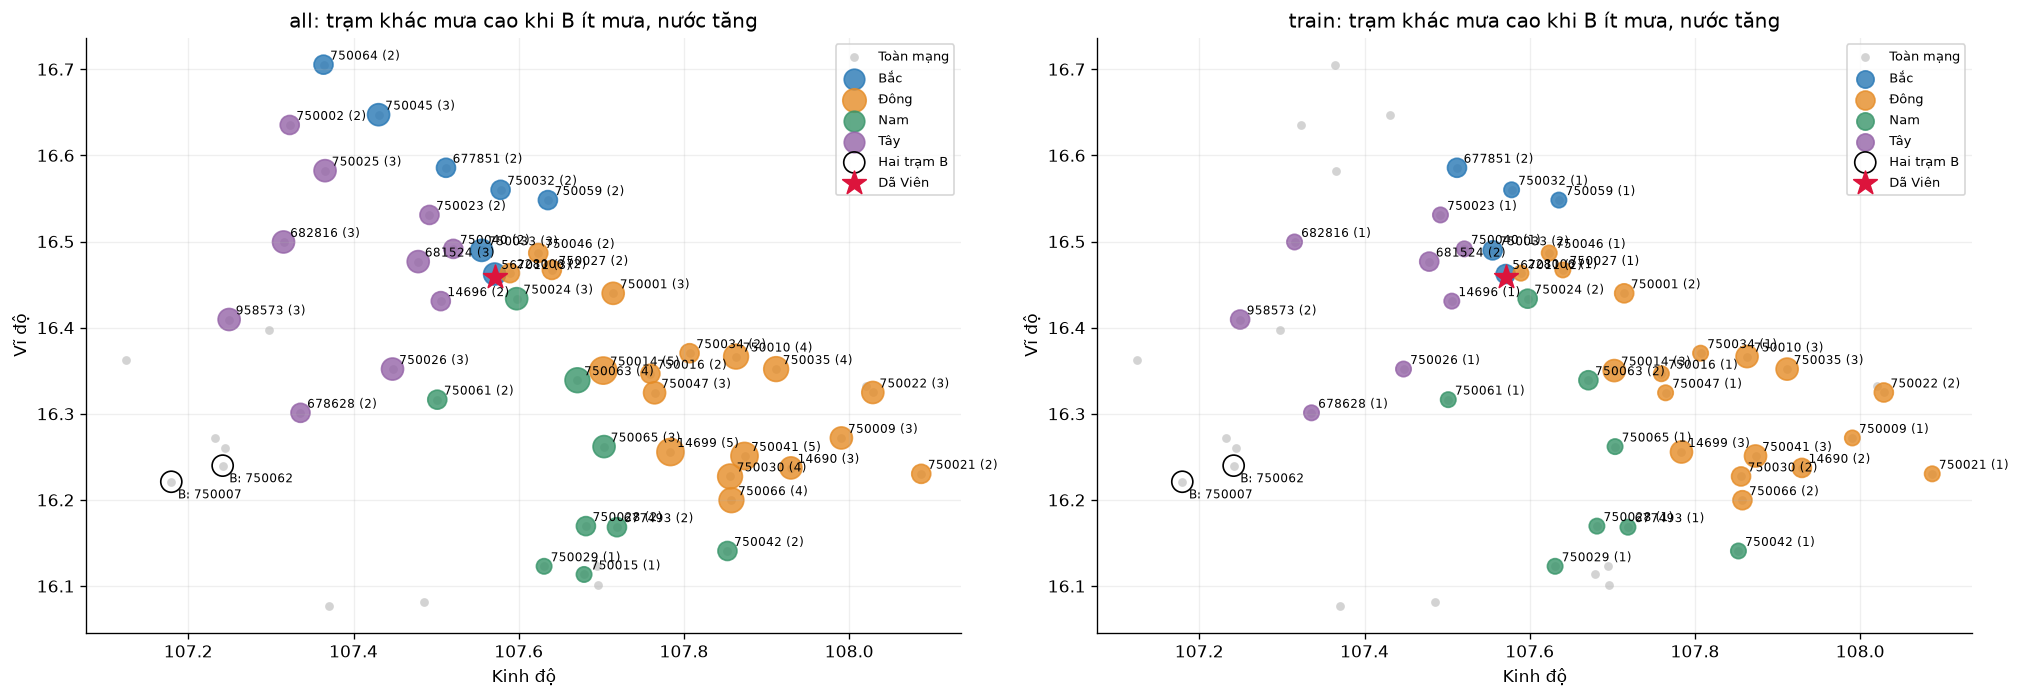

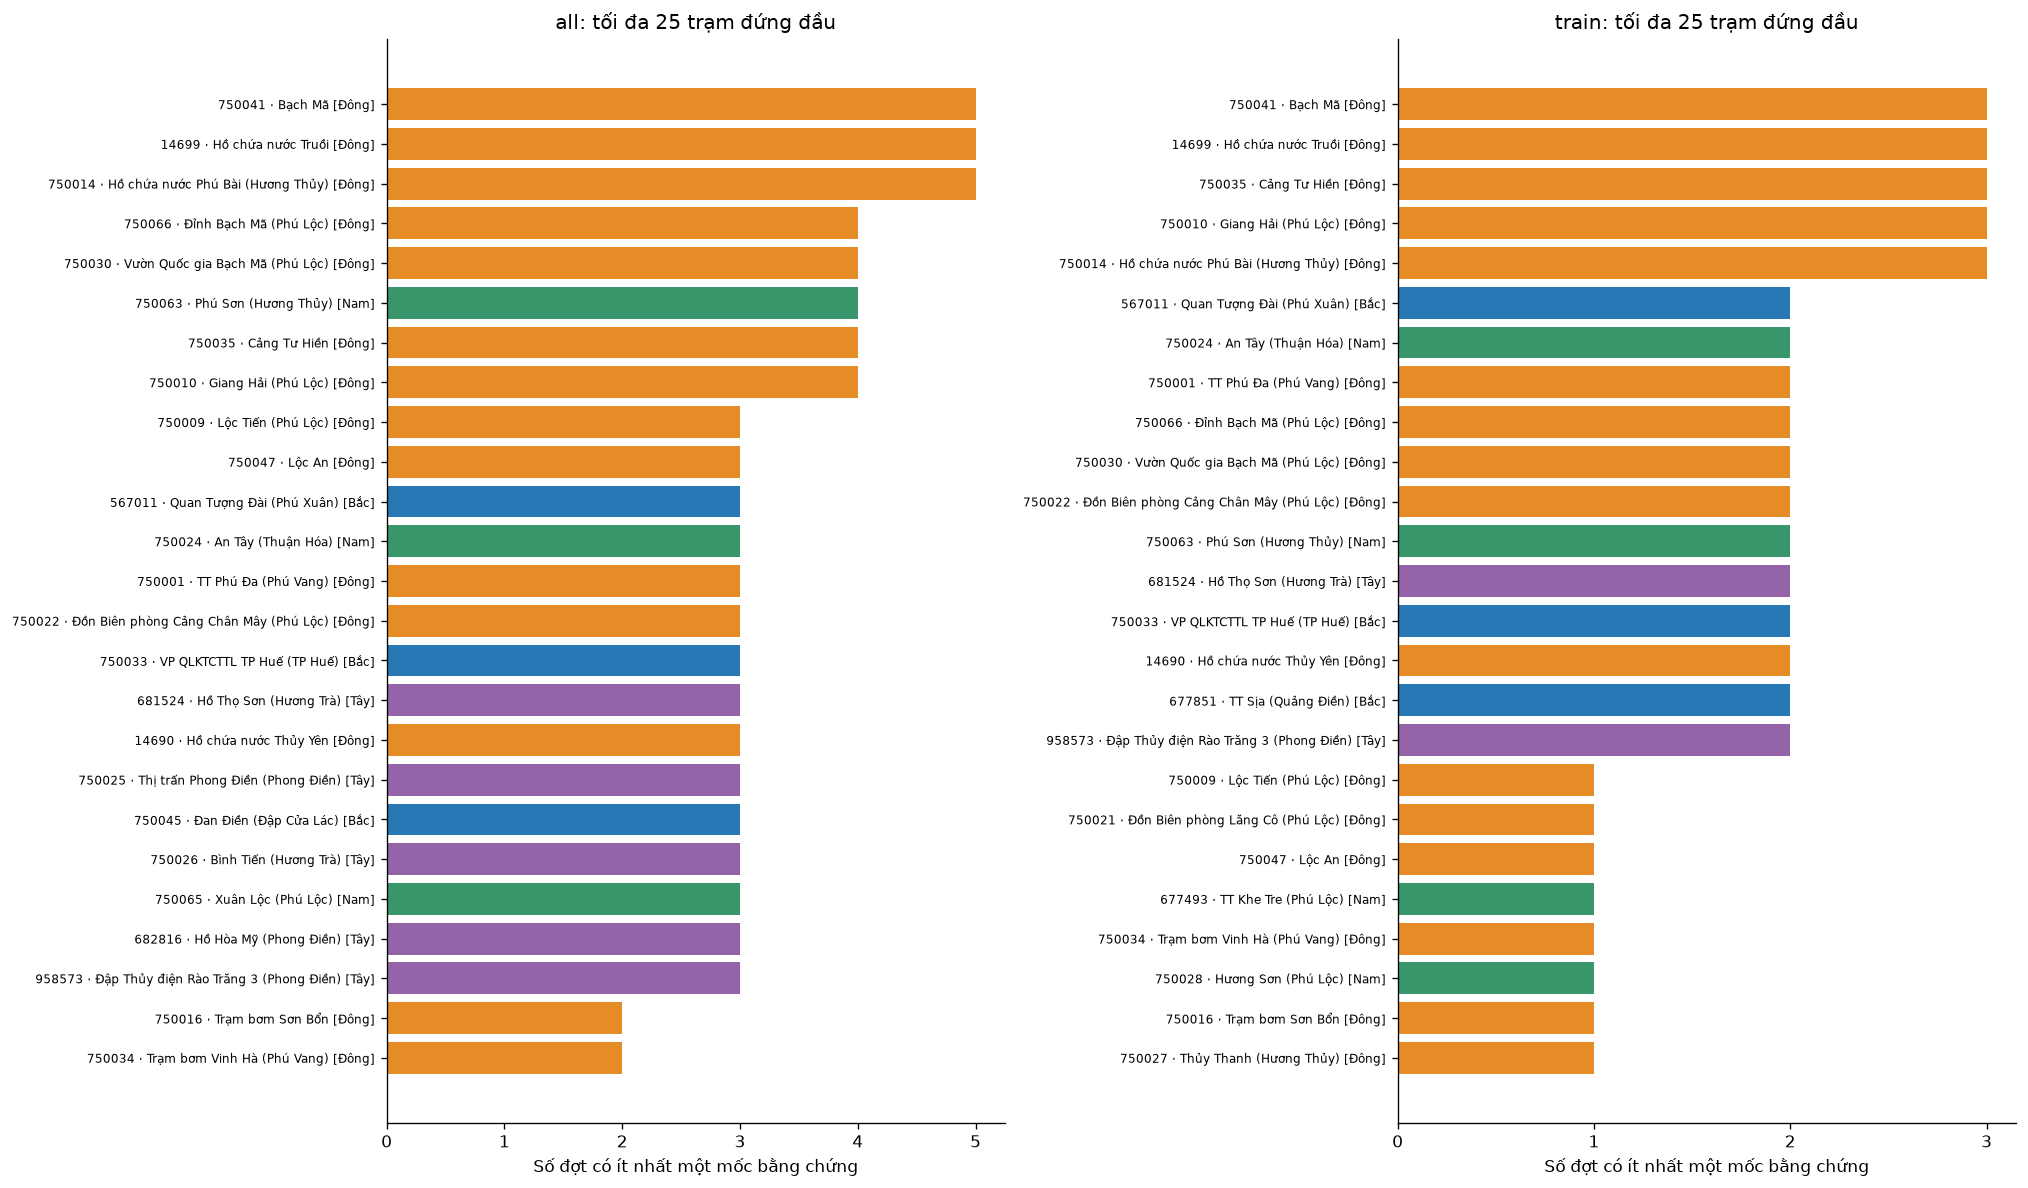

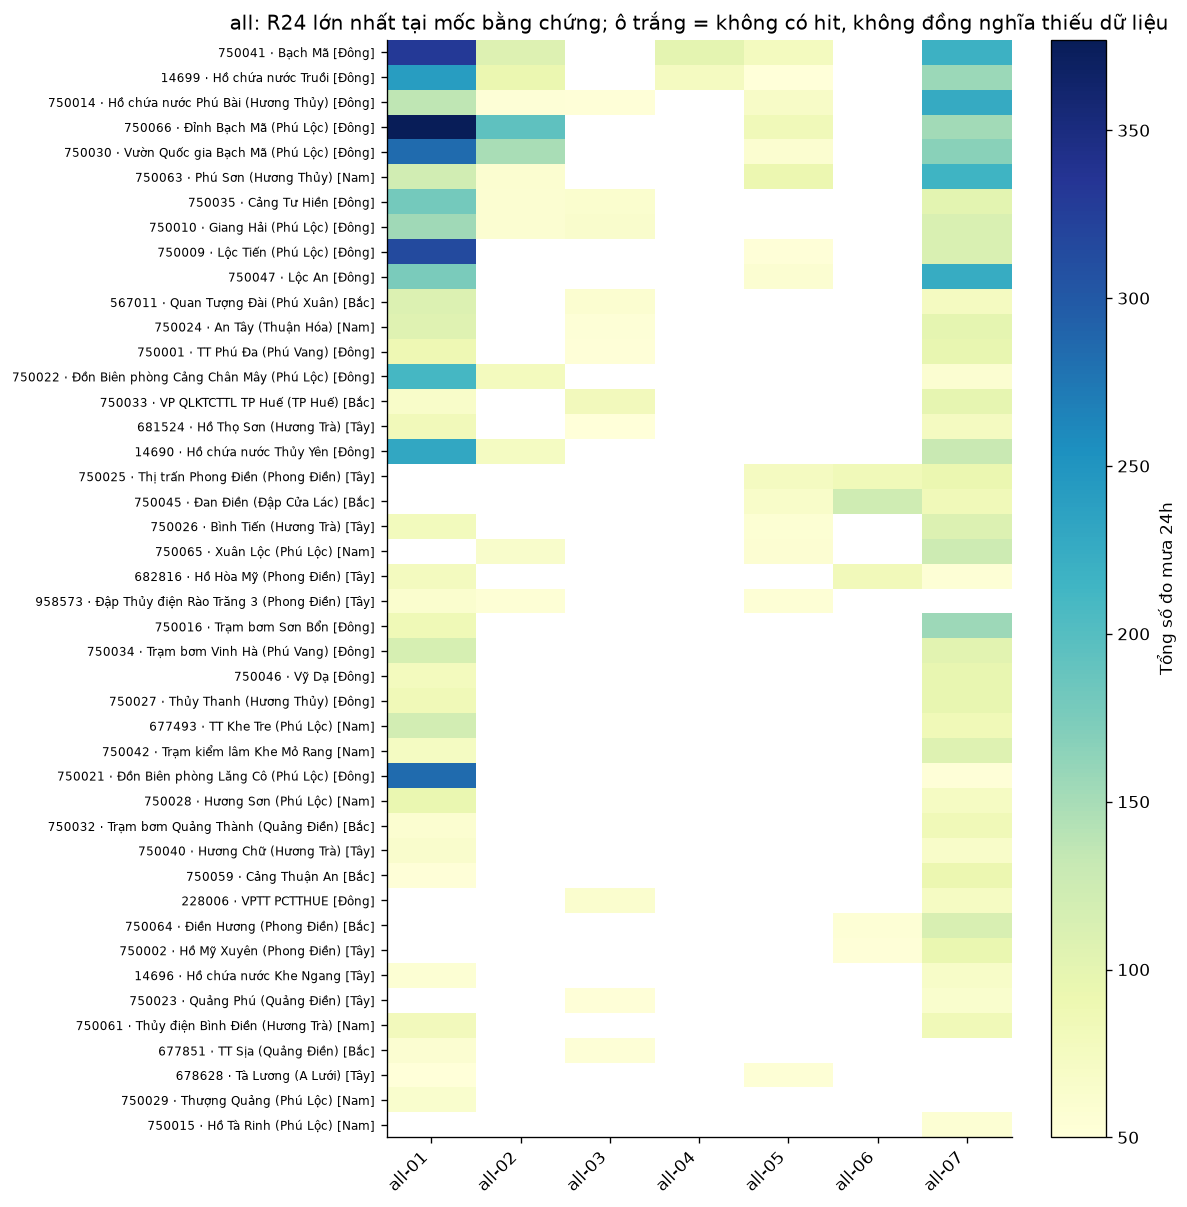

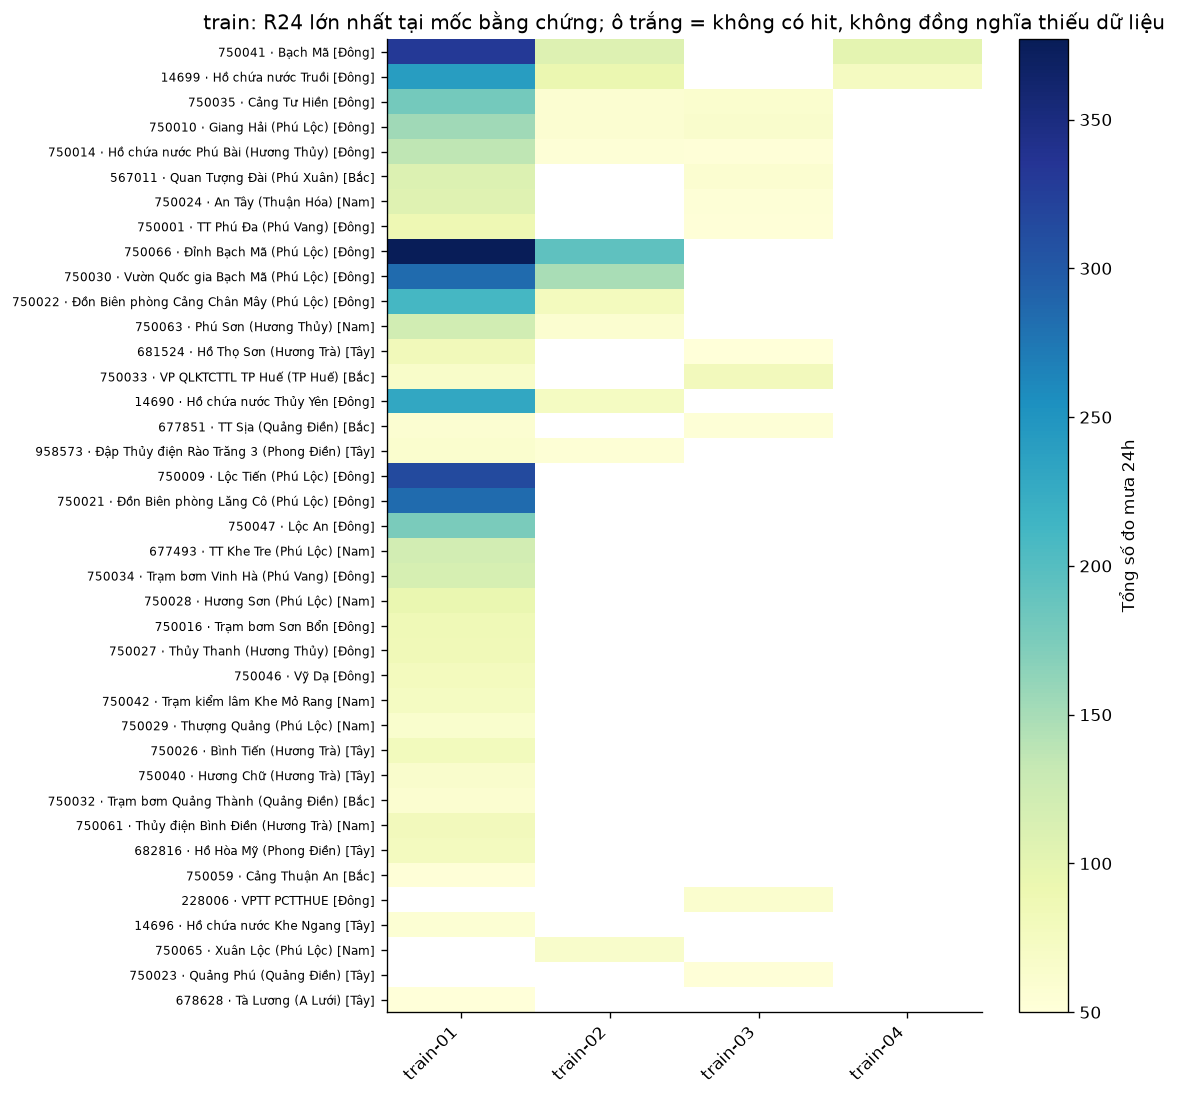

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for ax, scope_name in zip(axes, scopes):
    summary = station_summaries[scope_name]
    ax.scatter(catalog.longitude, catalog.latitude, color="lightgrey", s=18, label="Toàn mạng")
    for direction in DIRECTIONS:
        group = summary.loc[summary.direction.eq(direction)]
        if len(group):
            ax.scatter(group.longitude, group.latitude, s=40 + 45 * group.event_count,
                color=COLORS[direction], alpha=.8, label=direction)
    for _, row in summary.iterrows():
        ax.annotate(f"{row.station_id} ({row.event_count})", (row.longitude, row.latitude),
            xytext=(4, 3), textcoords="offset points", fontsize=7)
    b = catalog.loc[WEST]
    ax.scatter(b.longitude, b.latitude, facecolors="none", edgecolors="black", s=160, label="Hai trạm B")
    for sid, row in b.iterrows():
        ax.annotate(f"B: {sid}", (row.longitude, row.latitude), xytext=(4, -10), textcoords="offset points", fontsize=7)
    ax.scatter(LON0, LAT0, marker="*", color="crimson", s=220, label="Dã Viên")
    ax.set_aspect(1 / np.cos(lat0))
    ax.set(title=f"{scope_name}: trạm khác mưa cao khi B ít mưa, nước tăng", xlabel="Kinh độ", ylabel="Vĩ độ")
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.tight_layout()
show()

fig, axes = plt.subplots(1, 2, figsize=(17, 10))
for ax, scope_name in zip(axes, scopes):
    summary = station_summaries[scope_name].head(25).iloc[::-1]
    ax.barh(np.arange(len(summary)), summary.event_count, color=[COLORS.get(d, "grey") for d in summary.direction])
    ax.set_yticks(np.arange(len(summary)), [f"{r.station_id} · {r['name']} [{r.direction}]" for _, r in summary.iterrows()], fontsize=7)
    ax.set(title=f"{scope_name}: tối đa 25 trạm đứng đầu", xlabel="Số đợt có ít nhất một mốc bằng chứng")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.tight_layout()
show()

for scope_name in scopes:
    group = evidence.loc[evidence.scope.eq(scope_name)]
    if group.empty:
        continue
    matrix = group.pivot(index="station_id", columns="event_id", values="rain24")
    order = station_summaries[scope_name].station_id
    matrix = matrix.reindex(order)
    fig, ax = plt.subplots(figsize=(max(8, len(matrix.columns) * 1.2), max(5, len(matrix) * .27)))
    data = np.ma.masked_invalid(matrix.to_numpy(float))
    image = ax.imshow(data, aspect="auto", cmap="YlGnBu", vmin=OTHER_MIN_24H)
    ax.set_yticks(range(len(matrix)), [f"{sid} · {catalog.loc[sid, 'name']} [{catalog.loc[sid, 'direction']}]" for sid in matrix.index], fontsize=7)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_title(f"{scope_name}: R24 lớn nhất tại mốc bằng chứng; ô trắng = không có hit, không đồng nghĩa thiếu dữ liệu")
    fig.colorbar(image, ax=ax, label="Tổng số đo mưa 24h")
    show()

## 5. Đồ thị từng đợt
Vẽ tất cả đợt `all` một lần để tránh lặp hình khi train là tập con. Tiêu đề ghi các đợt train có mốc trùng. Panel trên là nước và mốc gắn cờ; panel dưới là R24 của **hai nguồn B và tối đa ba trạm khác** nổi bật. Toàn bộ trạm khác vẫn nằm trong bảng bằng chứng, không chỉ ba trạm được vẽ.

Vùng nền là khoảng đầu–cuối mốc gắn cờ, không mặc định là thời gian mưa hoặc toàn trận lũ. Các giờ ngoài vùng là bối cảnh hồi cứu; nếu có giờ validation/test trong hình `all`, chúng không được dùng cho bảng train. Các đường R24 đều là tổng lùi 24h tại từng mốc.


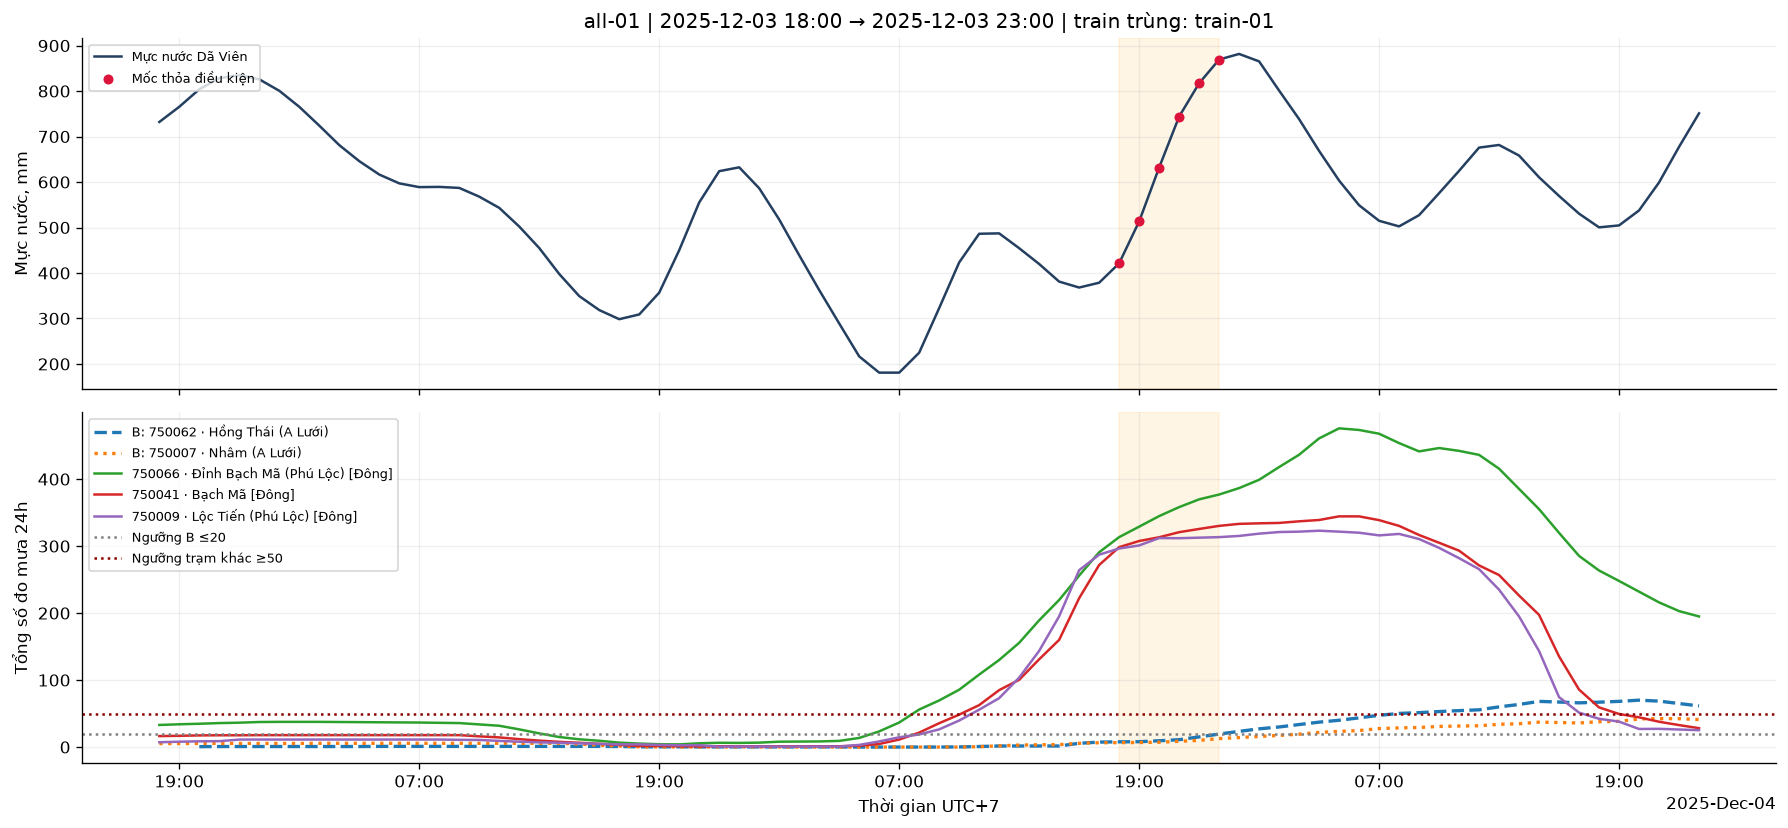

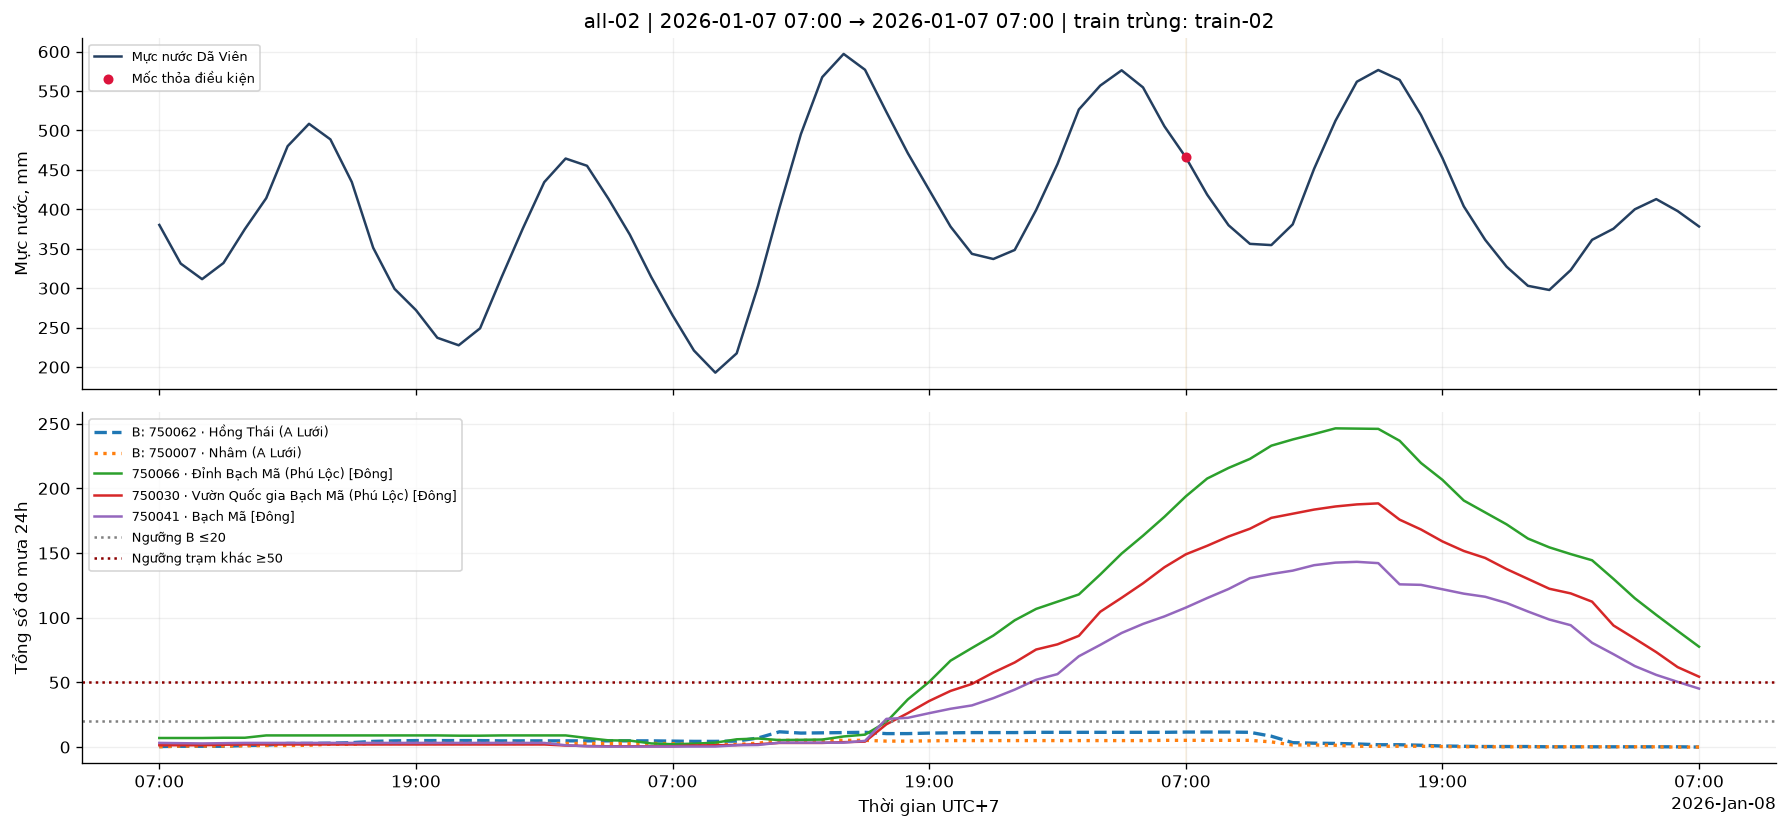

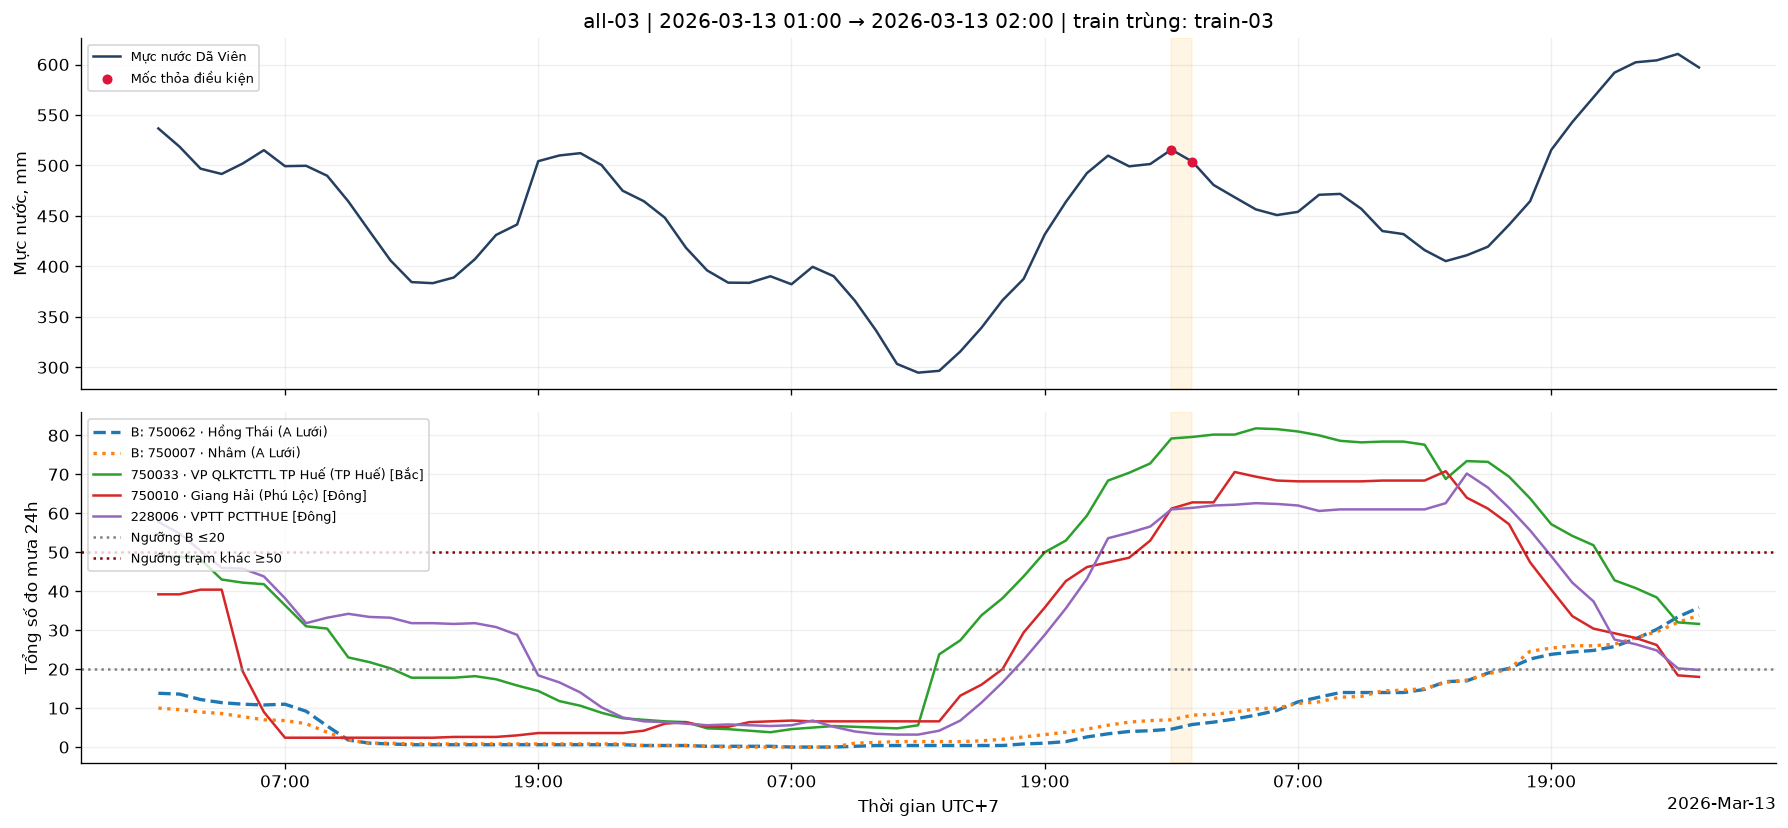

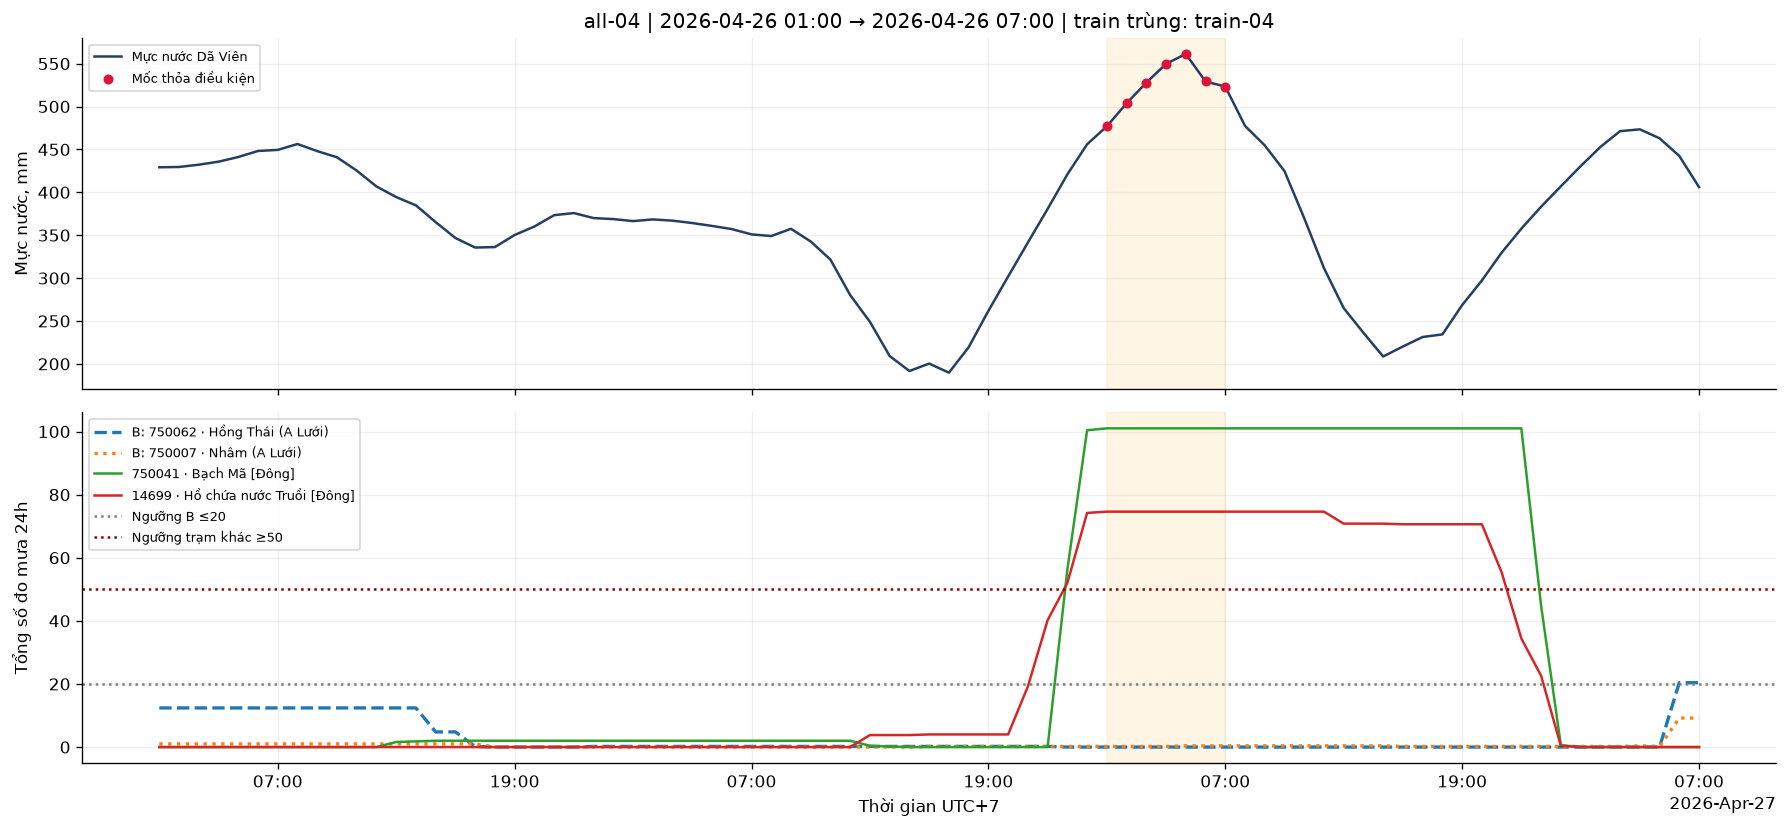

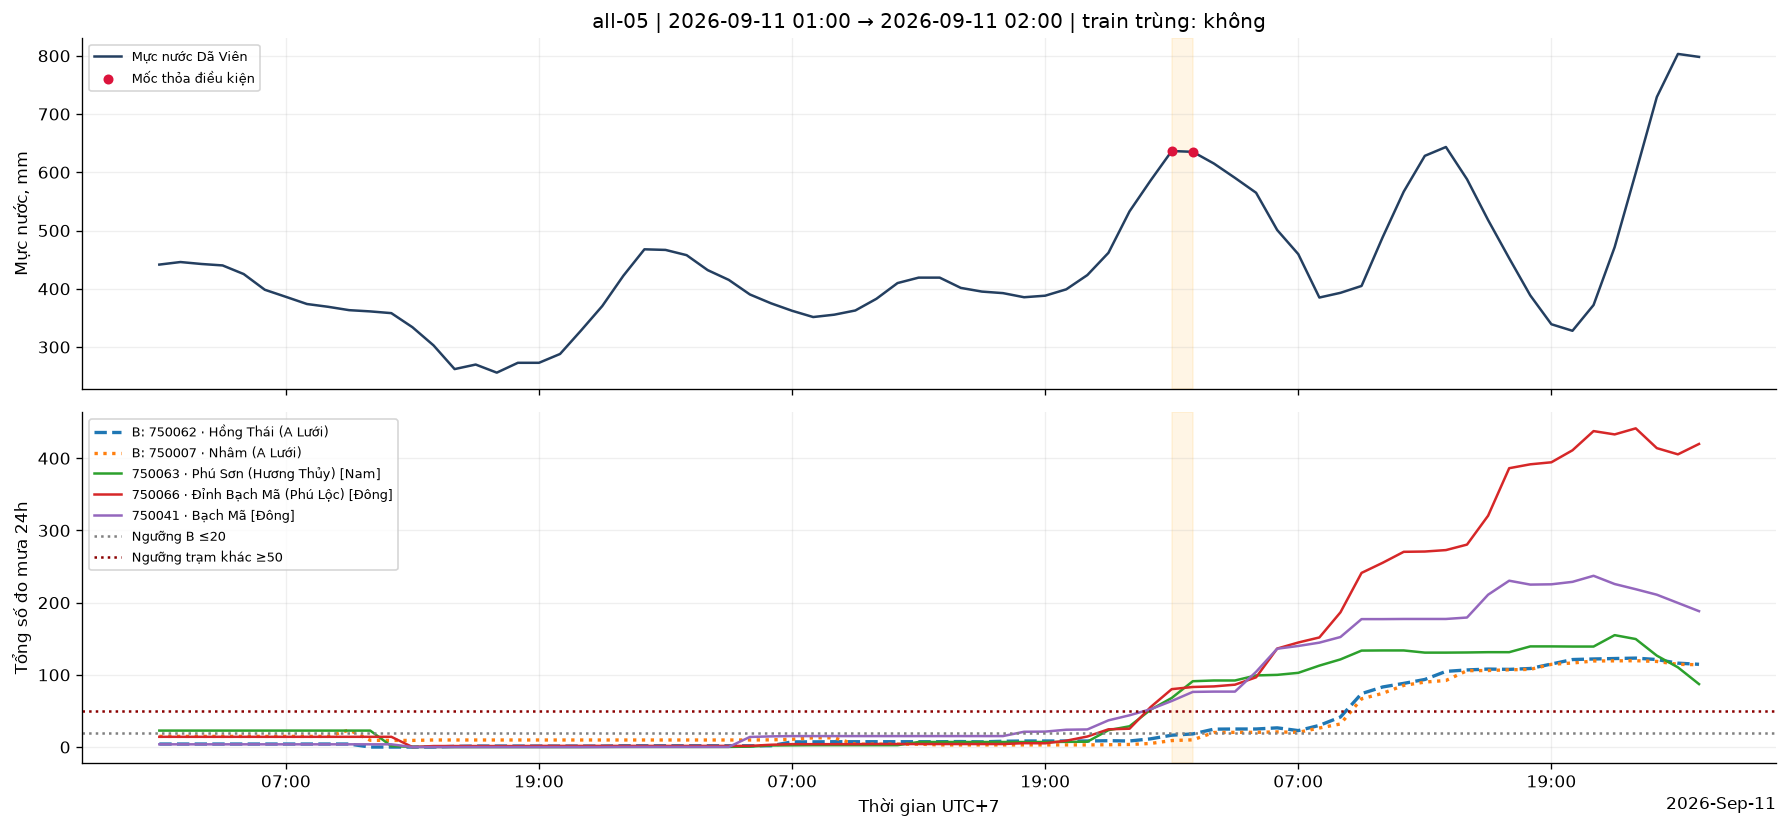

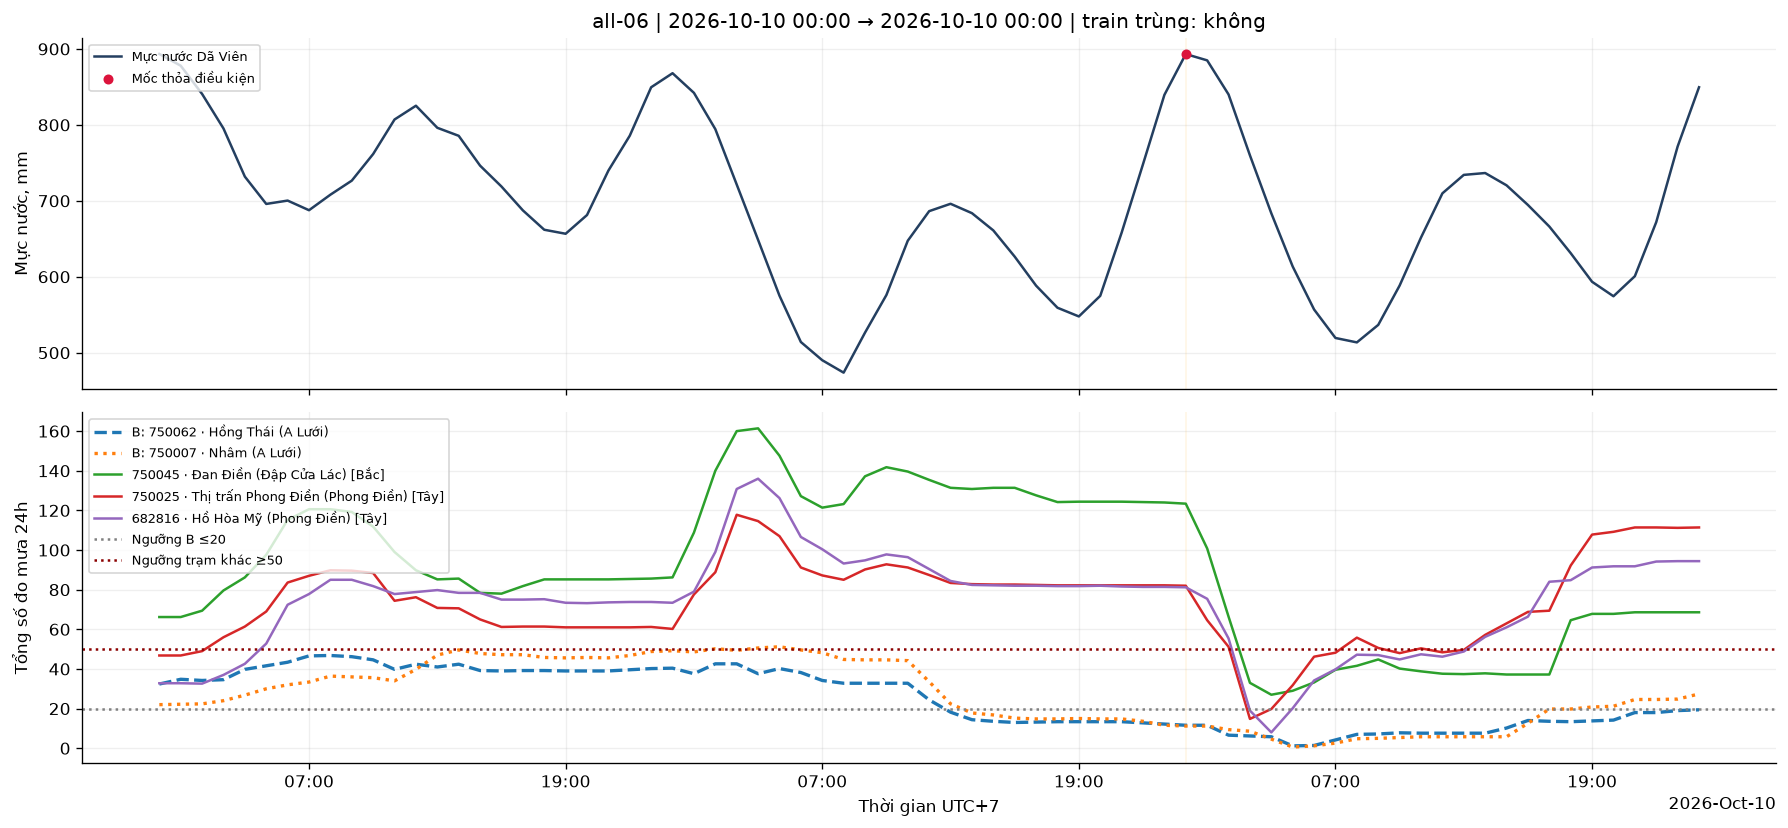

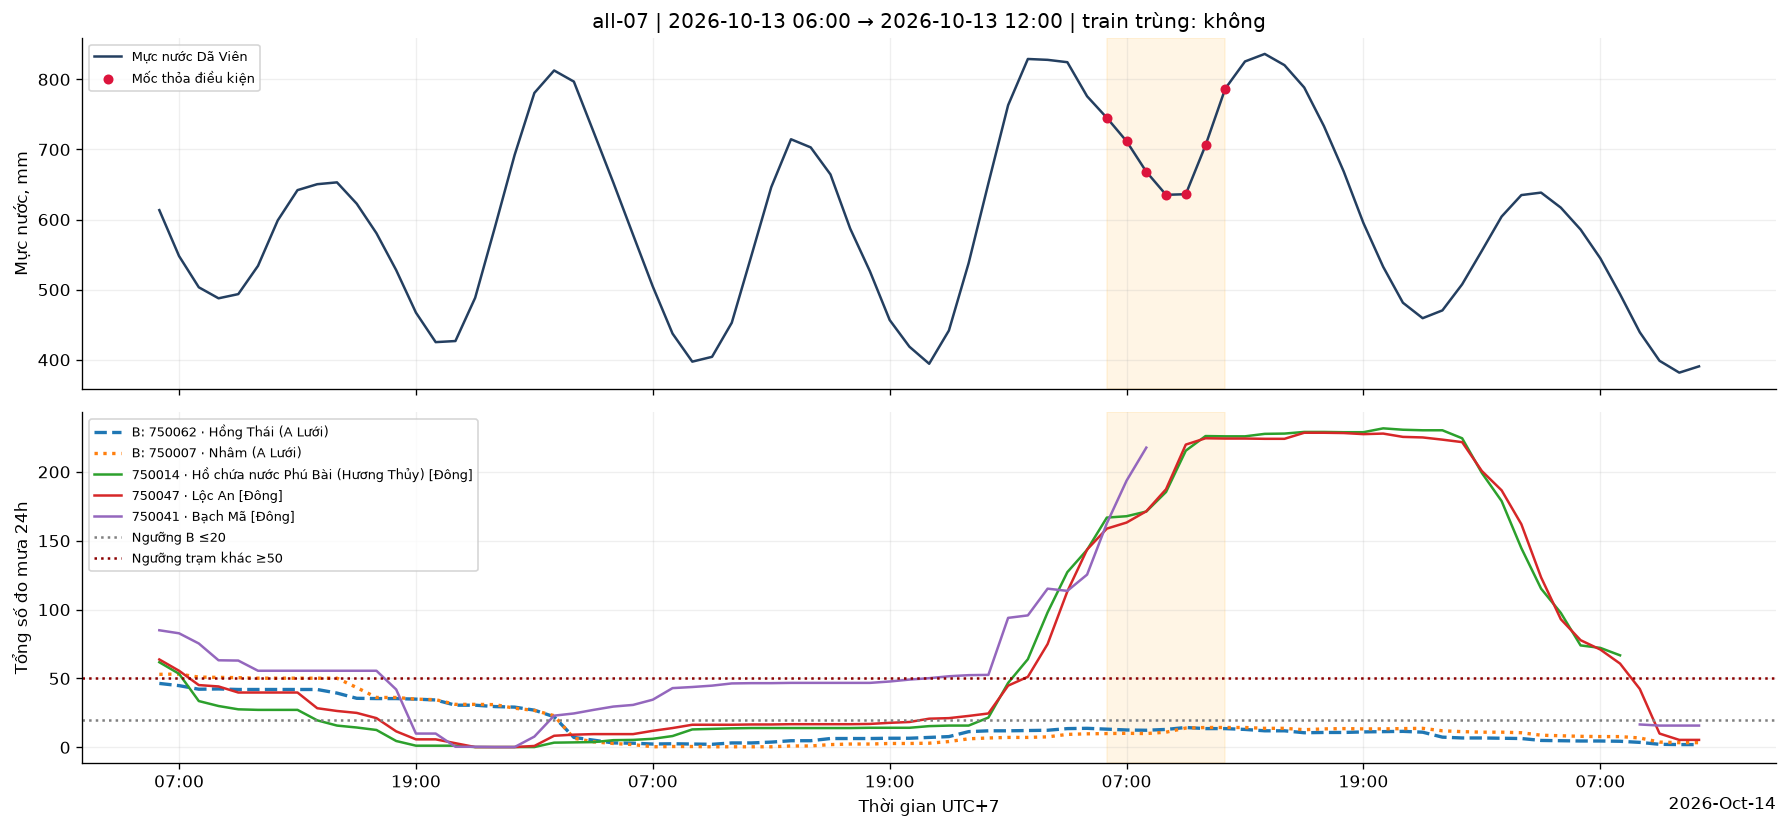

In [7]:
for _, event in events.loc[events.scope.eq("all")].iterrows():
    times = event_times[("all", event.event_id)]
    left = max(index.min(), times.min() - pd.Timedelta(hours=48))
    right = min(index.max(), times.max() + pd.Timedelta(hours=24))
    segment = index[(index >= left) & (index <= right)]
    top = evidence.loc[evidence.scope.eq("all") & evidence.event_id.eq(event.event_id)].nlargest(3, "rain24")
    linked_train = [event_id for (scope_name, event_id), train_times in event_times.items()
        if scope_name == "train" and len(times.intersection(train_times))]
    fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
    axes[0].plot(segment.tz_convert(TZ), water.loc[segment], color="#243f60", label="Mực nước Dã Viên")
    axes[0].scatter(times.tz_convert(TZ), water.loc[times], color="crimson", s=25, label="Mốc thỏa điều kiện", zorder=4)
    axes[0].set_ylabel("Mực nước, mm")
    axes[0].set_title(f"{event.event_id} | {event.start_local} → {event.end_local} | train trùng: {', '.join(linked_train) or 'không'}")
    for sid, style in zip(WEST, ["--", ":"]):
        axes[1].plot(segment.tz_convert(TZ), rain24.loc[segment, sid], linestyle=style,
            linewidth=2, label=f"B: {sid} · {catalog.loc[sid, 'name']}")
    for _, station in top.iterrows():
        sid = station.station_id
        axes[1].plot(segment.tz_convert(TZ), rain24.loc[segment, sid],
            label=f"{sid} · {station['name']} [{station.direction}]")
    axes[1].axhline(WEST_MAX_24H, color="grey", linestyle=":", label=f"Ngưỡng B ≤{WEST_MAX_24H:g}")
    axes[1].axhline(OTHER_MIN_24H, color="darkred", linestyle=":", label=f"Ngưỡng trạm khác ≥{OTHER_MIN_24H:g}")
    axes[1].set_ylabel("Tổng số đo mưa 24h")
    axes[1].set_xlabel("Thời gian UTC+7")
    for ax in axes:
        ax.axvspan(times.min().tz_convert(TZ), times.max().tz_convert(TZ), color="orange", alpha=.10)
        ax.grid(alpha=.2)
        ax.legend(loc="upper left", fontsize=8)
    locator = mdates.AutoDateLocator()
    axes[1].xaxis.set_major_locator(locator)
    axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=TZ))
    fig.tight_layout()
    show()

## 6. Độ nhạy của kết quả với ngưỡng
Không điều chỉnh ngưỡng theo validation/test để lựa chọn nguồn. Bảng sau cho biết số đợt thay đổi thế nào nếu tăng nước ≥200/400/600 mm, hai trạm B ≤10/20/30, trạm khác ≥30/50/100. Giữ nguyên cách lọc dữ liệu thiếu và gộp đợt. Nếu kết quả chỉ có ở ngưỡng rất lỏng thì bằng chứng yếu hơn; số đợt không đồng nghĩa số trận mưa độc lập.


In [8]:
sensitivity_rows = []
for scope_name, scope in scopes.items():
    for rise_min in [200, 400, 600]:
        for west_max in [10, 20, 30]:
            for other_min in [30, 50, 100]:
                _, matched, _, _ = condition_masks(scope, rise_min, west_max, other_min)
                sensitivity_rows.append(dict(scope=scope_name, rise_min=rise_min, west_max=west_max,
                    other_min=other_min, hours=int(matched.sum()), events=len(event_groups(index[matched]))))
sensitivity = pd.DataFrame(sensitivity_rows)
for scope_name in scopes:
    print(scope_name, "— số đợt; hàng = (mức tăng nước, trần mưa B), cột = sàn mưa trạm khác")
    display(sensitivity.loc[sensitivity.scope.eq(scope_name)].pivot(index=["rise_min", "west_max"], columns="other_min", values="events"))

all — số đợt; hàng = (mức tăng nước, trần mưa B), cột = sàn mưa trạm khác
train — số đợt; hàng = (mức tăng nước, trần mưa B), cột = sàn mưa trạm khác


other_min          30   50   100
rise_min west_max               
200      10          5    3    2
         20          9    7    5
         30         11    8    6
400      10          1    1    1
         20          1    1    1
         30          1    1    1
600      10          0    0    0
         20          0    0    0
         30          0    0    0

other_min          30   50   100
rise_min west_max               
200      10          5    3    2
         20          6    4    3
         30          7    4    3
400      10          1    1    1
         20          1    1    1
         30          1    1    1
600      10          0    0    0
         20          0    0    0
         30          0    0    0

## 7. Kiểm tra nhất quán và kết luận tự cập nhật
Kiểm tra cả dữ liệu thật và các ví dụ nhỏ: thiếu một giờ không tạo được R24; đúng biên 6h được gộp, xa hơn tách đợt; mọi bằng chứng có nước tăng và hai nguồn B thấp **tại cùng timestamp**. Bằng chứng train không được dùng lịch sử ngoài train.


In [9]:
assert index.is_unique and index.is_monotonic_increasing
assert index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
example = pd.Series(np.ones(48))
example.iloc[20] = np.nan
assert pd.isna(example.rolling(24, min_periods=24).sum().iloc[23])
assert example.rolling(24, min_periods=24).sum().iloc[-1] == 24
synthetic_times = pd.date_range("2026-01-01", periods=3, freq="6h", tz="UTC")
assert len(event_groups(synthetic_times)) == 1
assert len(event_groups([synthetic_times[0], synthetic_times[0] + pd.Timedelta(hours=7)])) == 2
assert not (qualified_masks["train"] & ~qualified_masks["all"]).any()
for _, row in evidence.iterrows():
    t = pd.Timestamp(row.time_local).tz_localize(TZ).tz_convert("UTC")
    assert qualified_masks[row.scope].loc[t]
    assert rain24.loc[t, WEST].notna().all()
    assert rain24.loc[t, WEST].le(WEST_MAX_24H).all()
    assert rain24.loc[t, row.station_id] >= OTHER_MIN_24H
    assert rises.loc[t].ge(RISE_MIN_MM).any()
    if row.scope == "train":
        assert t - pd.Timedelta(hours=24) >= train_start and t <= train_end
assert not evidence.duplicated(["scope", "event_id", "station_id"]).any()
assert not events.duplicated(["scope", "event_id"]).any()
print("PASS: lưới giờ, cửa sổ thiếu, gộp đợt, bằng chứng đồng thời và ranh train.")

lines = ["### Kết quả theo ngưỡng cấu hình"]
for scope_name in scopes:
    group = events.loc[events.scope.eq(scope_name)]
    hits = evidence.loc[evidence.scope.eq(scope_name)]
    lines.append(f"- **{scope_name}: {len(group)} đợt, {int(qualified_masks[scope_name].sum())} mốc giờ, {hits.station_id.nunique()} trạm khác có bằng chứng.**")
    for _, row in station_summaries[scope_name].head(5).iterrows():
        lines.append(f"  - {row.station_id} — {row['name']}, hướng **{row.direction}**, cách Dã Viên {row.distance_km:.1f} km: {row.event_count} đợt, R24 cao nhất {row.max_rain24:.1f}.")
lines += ["", "Các bảng sự kiện và bằng chứng cho biết chính xác thời điểm, địa chỉ, tọa độ và mưa tại hai nguồn B cùng mốc.",
    "", "Kết quả xác nhận sự đồng xuất hiện trong dữ liệu, không xác nhận nguồn gây tăng nước. Cần đối chiếu lưu vực, mưa xa hơn 24h, vận hành hồ, điều kiện hạ lưu và đo kiểm trước khi thay nguồn hoặc giải thích lỗi Model B."]
display(Markdown("\n".join(lines)))

PASS: lưới giờ, cửa sổ thiếu, gộp đợt, bằng chứng đồng thời và ranh train.


### Kết quả theo ngưỡng cấu hình
- **all: 7 đợt, 26 mốc giờ, 44 trạm khác có bằng chứng.**
  - 750041 — Bạch Mã, hướng **Đông**, cách Dã Viên 39.7 km: 5 đợt, R24 cao nhất 330.2.
  - 14699 — Hồ chứa nước Truồi, hướng **Đông**, cách Dã Viên 32.0 km: 5 đợt, R24 cao nhất 240.6.
  - 750014 — Hồ chứa nước Phú Bài (Hương Thủy), hướng **Đông**, cách Dã Viên 18.5 km: 5 đợt, R24 cao nhất 226.0.
  - 750066 — Đỉnh Bạch Mã (Phú Lộc), hướng **Đông**, cách Dã Viên 42.0 km: 4 đợt, R24 cao nhất 377.0.
  - 750030 — Vườn Quốc gia Bạch Mã (Phú Lộc), hướng **Đông**, cách Dã Viên 39.8 km: 4 đợt, R24 cao nhất 284.4.
- **train: 4 đợt, 16 mốc giờ, 39 trạm khác có bằng chứng.**
  - 750041 — Bạch Mã, hướng **Đông**, cách Dã Viên 39.7 km: 3 đợt, R24 cao nhất 330.2.
  - 14699 — Hồ chứa nước Truồi, hướng **Đông**, cách Dã Viên 32.0 km: 3 đợt, R24 cao nhất 240.6.
  - 750035 — Cảng Tư Hiền, hướng **Đông**, cách Dã Viên 38.2 km: 3 đợt, R24 cao nhất 179.2.
  - 750010 — Giang Hải (Phú Lộc), hướng **Đông**, cách Dã Viên 32.8 km: 3 đợt, R24 cao nhất 153.8.
  - 750014 — Hồ chứa nước Phú Bài (Hương Thủy), hướng **Đông**, cách Dã Viên 18.5 km: 3 đợt, R24 cao nhất 135.6.

Các bảng sự kiện và bằng chứng cho biết chính xác thời điểm, địa chỉ, tọa độ và mưa tại hai nguồn B cùng mốc.

Kết quả xác nhận sự đồng xuất hiện trong dữ liệu, không xác nhận nguồn gây tăng nước. Cần đối chiếu lưu vực, mưa xa hơn 24h, vận hành hồ, điều kiện hạ lưu và đo kiểm trước khi thay nguồn hoặc giải thích lỗi Model B.